In [22]:
!pip install kaggle

In [23]:
import os

# Create .kaggle directory if it doesn't exist
!mkdir -p ~/.kaggle

# Move kaggle.json to the .kaggle directory (assuming you uploaded it to /content/)
!mv kaggle.json ~/.kaggle/

# Set permissions (important for security)
!chmod 600 ~/.kaggle/kaggle.json

print("Kaggle API key configured successfully.")

The syntax of the command is incorrect.
'mv' is not recognized as an internal or external command,
operable program or batch file.


Kaggle API key configured successfully.


'chmod' is not recognized as an internal or external command,
operable program or batch file.


In [24]:
!kaggle datasets download -d sumn2u/garbage-classification-v2

Dataset URL: https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2
License(s): MIT
garbage-classification-v2.zip: Skipping, found more recently modified local copy (use --force to force download)


In [25]:
import zipfile
import os

# List contents to find the zip file name (it's usually the dataset name + .zip)
# You might need to adjust 'garbage-classification-v2.zip' if the name is different
zip_file_name = 'garbage-classification-v2.zip'

# Create a directory for the dataset if it doesn't exist
dataset_target_path = '/content/garbage-classification-v2'
os.makedirs(dataset_target_path, exist_ok=True)

# Unzip the file
with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall(dataset_target_path)

print(f"Dataset unzipped to {dataset_target_path}")
print(f"Contents of {dataset_target_path}: {os.listdir(dataset_target_path)}")

Dataset unzipped to /content/garbage-classification-v2
Contents of /content/garbage-classification-v2: ['original', 'standardized_256', 'standardized_384']


In [27]:
import os
import numpy as np
import pandas as pd # Import pandas for DataFrame
from sklearn.model_selection import train_test_split 
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# -----------------------------
# AUTO DETECT DATASET PATH
# -----------------------------
base_path = "/content/garbage-classification-v2"

# Check if the base path exists after modification
if not os.path.exists(base_path):
    raise FileNotFoundError(f"Dataset base path not found: {base_path}. Please ensure the dataset is uploaded or mounted correctly.")

folders = os.listdir(base_path)
print("Inside dataset:", folders)

dataset_path = os.path.join(base_path, folders[0])  # auto pick correct folder (e.g., 'standardized_256')
print("Using path:", dataset_path)


# -----------------------------
# LOAD DATASET (collect file paths and labels)
# -----------------------------
def load_dataset_info(path):
    filepaths = []
    labels = []
    for class_name in os.listdir(path):
        class_path = os.path.join(path, class_name)
        if os.path.isdir(class_path):
            for img_name in os.listdir(class_path):
                filepaths.append(os.path.join(class_path, img_name))
                labels.append(class_name)
    return pd.DataFrame({'filepath': filepaths, 'label': labels})


# -----------------------------
# PREPROCESS & SPLIT
# -----------------------------
def preprocess_and_split_data(df, img_size=(224, 224), batch_size=32, train_split=0.7, val_split=0.15, test_split=0.15):

    # Ensure splits sum to 1
    if not (train_split + val_split + test_split == 1.0):
        raise ValueError("Train, validation, and test splits must sum to 1.0")

    # Initial split: train+val vs test
    train_val_df, test_df = train_test_split(
        df, test_size=test_split, stratify=df['label'], random_state=42
    )

    # Second split: train vs val from train+val_df
    train_df, val_df = train_test_split(
        train_val_df, test_size=val_split/(train_split + val_split), stratify=train_val_df['label'], random_state=42
    )

    # Create ImageDataGenerators (no validation_split here, as we've split dataframes)
    train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # 👈 THIS uses it
    rotation_range=40,
    zoom_range=0.3,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.5, 1.5],
    fill_mode='nearest',
    channel_shift_range=30
)
 
    
    val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)
    test_datagen =ImageDataGenerator(
    preprocessing_function=preprocess_input
)
   



    # Flow from DataFrame
    train_data = train_datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col='filepath',
        y_col='label',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True
    )

    val_data = val_datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col='filepath',
        y_col='label',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False # No need to shuffle validation data
    )

    test_data = test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col='filepath',
        y_col='label',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False # No need to shuffle test data
    )

    return train_data, val_data, test_data


# -----------------------------
# RUN
# -----------------------------
df_info = load_dataset_info(dataset_path)
print(f"Total images found: {len(df_info)}")

# Filter out unwanted classes
unwanted_classes = ['battery', 'biological', 'shoes', 'clothes'] # Added 'clothes'
df_info = df_info[~df_info['label'].isin(unwanted_classes)]
print(f"Total images after filtering: {len(df_info)}")

train_data, val_data, test_data = preprocess_and_split_data(df_info)

print("Number of classes:", len(train_data.class_indices))
print("Train images:", train_data.samples)
print("Validation images:", val_data.samples)
print("Test images:", test_data.samples)
print("Classes:", train_data.class_indices)

Inside dataset: ['original', 'standardized_256', 'standardized_384']
Using path: /content/garbage-classification-v2\original
Total images found: 12259
Total images after filtering: 7463
Found 5223 validated image filenames belonging to 6 classes.
Found 1120 validated image filenames belonging to 6 classes.
Found 1120 validated image filenames belonging to 6 classes.
Number of classes: 6
Train images: 5223
Validation images: 1120
Test images: 1120
Classes: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


In [28]:
# Define model parameters
image_height, image_width = train_data.target_size
num_channels = 3 # RGB images
input_shape = (image_height, image_width, num_channels)
num_classes = len(train_data.class_indices)

print(f"Input Shape: {input_shape}")
print(f"Number of Classes: {num_classes}")

Input Shape: (224, 224, 3)
Number of Classes: 6


In [29]:








import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2 # Changed from EfficientNetB0
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout,GaussianNoise

# ==============================
# Build MobileNetV2 Model
# ==============================
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=input_shape
)

base_model.trainable = False  # Freeze base model

model = Sequential([
    base_model,
    GaussianNoise(0.1),
    GlobalAveragePooling2D(),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model Summary:")
model.summary()

Model Summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_1                │ (None, 7, 7, 1280)     │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Reasoning**:
Train the MobileNetV2 based model using the preprocessed `train_data` and `val_data` for a specified number of epochs, storing the training history.



In [38]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

epochs = 50

# Define EarlyStopping callback
early_stopping = EarlyStopping(
    monitor='val_loss', # Monitor validation loss
    patience=10,        # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True # Restore model weights from the epoch with the best value of the monitored quantity
)

# Define ModelCheckpoint callback
checkpoint_filepath = 'best_model.keras'
model_checkpoint = ModelCheckpoint(
    filepath=checkpoint_filepath,
    monitor='val_loss', # Monitor validation loss
    save_best_only=True, # Save only the best model
    mode='min',         # Save model when validation loss is minimum
    verbose=1           # Log when a model is saved
)

history = model.fit(
    train_data,
    epochs=epochs,
    validation_data=val_data,
    callbacks=[early_stopping, model_checkpoint] # Add callbacks here
)

print("Model training complete.")

Epoch 1/50
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 919ms/step - accuracy: 0.8185 - loss: 0.4997
Epoch 1: val_loss improved from None to 0.39284, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
164/164 ━━━━━━━━━━━━━━━━━━━━ 179s 1s/step - accuracy: 0.8105 - loss: 0.5125 - val_accuracy: 0.8652 - val_loss: 0.3928
Epoch 2/50
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 621ms/step - accuracy: 0.8346 - loss: 0.4612
Epoch 2: val_loss improved from 0.39284 to 0.38353, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
164/164 ━━━━━━━━━━━━━━━━━━━━ 114s 691ms/step - accuracy: 0.8311 - loss: 0.4779 - val_accuracy: 0.8661 - val_loss: 0.3835
Epoch 3/50
164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 610ms/step - accuracy: 0.8367 - loss: 0.4523
Epoch 3: val_loss improved from 0.38353 to 0.37403, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
164/164 ━━━━━━━━━━━━━━━━━━━━ 111s 677ms/step - accuracy: 0.8329 - loss: 0.4546 - val_accu

In [32]:
from tensorflow.keras.models import load_model
model = load_model("best_model.keras")

35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 348ms/step - accuracy: 0.9107 - loss: 0.2817
Test Loss: 0.2817
Test Accuracy: 0.9107
35/35 ━━━━━━━━━━━━━━━━━━━━ 13s 311ms/step

Classification Report:
               precision    recall  f1-score   support

   cardboard       0.93      0.97      0.95       212
       glass       0.92      0.90      0.91       260
       metal       0.89      0.96      0.92       140
       paper       0.94      0.91      0.92       200
     plastic       0.89      0.88      0.88       240
       trash       0.84      0.78      0.81        68

    accuracy                           0.91      1120
   macro avg       0.90      0.90      0.90      1120
weighted avg       0.91      0.91      0.91      1120



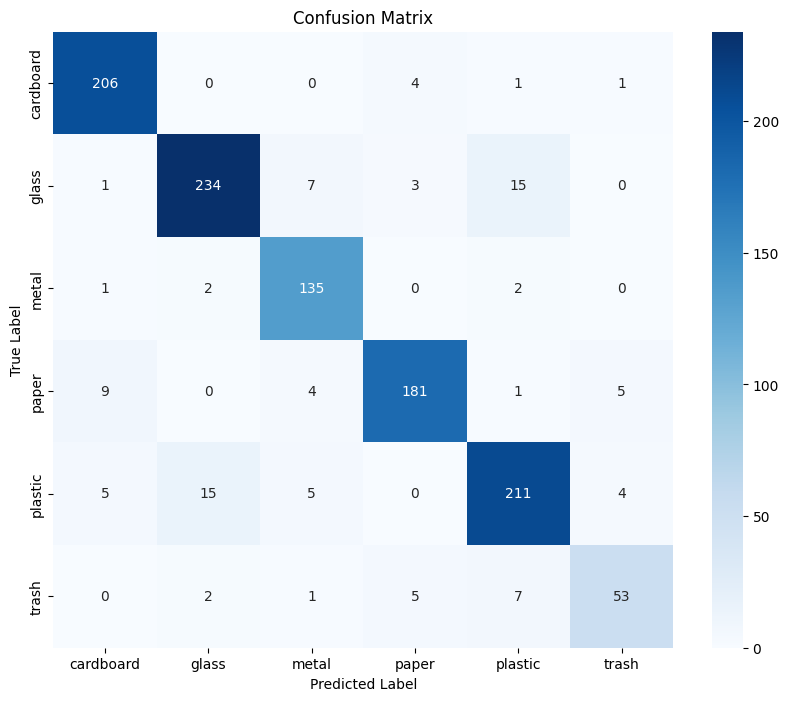

In [39]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(test_data)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Get predictions
predictions_prob = model.predict(test_data)
predictions_classes = np.argmax(predictions_prob, axis=1)

# Get true labels
true_classes = test_data.classes
class_labels = list(test_data.class_indices.keys())

# Generate classification report
report = classification_report(true_classes, predictions_classes, target_names=class_labels)
print("\nClassification Report:\n", report)

# Generate confusion matrix
conf_matrix = confusion_matrix(true_classes, predictions_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


## ROC Curve and AUC Score

The Receiver Operating Characteristic (ROC) curve is a graphical plot that illustrates the diagnostic ability of a binary classifier system as its discrimination threshold is varied. The Area Under the Curve (AUC) provides an aggregate measure of performance across all possible classification thresholds.

35/35 ━━━━━━━━━━━━━━━━━━━━ 12s 333ms/step


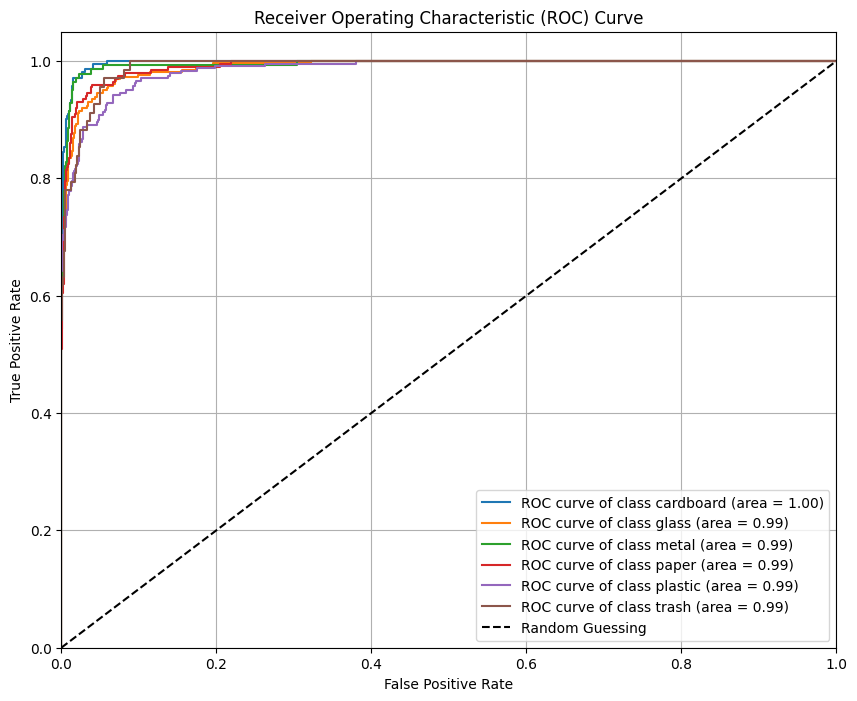

AUC for each class:
  Class cardboard: 1.00
  Class glass: 0.99
  Class metal: 0.99
  Class paper: 0.99
  Class plastic: 0.99
  Class trash: 0.99


In [41]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np # Import numpy here

# Get true labels and predicted probabilities for the test set
true_labels = np.array(test_data.classes) # Convert to numpy array
predicted_probabilities = model.predict(test_data)

# Get the number of classes and class names
num_classes = len(class_labels)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(true_labels == i, predicted_probabilities[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC curve of class {class_labels[i]} (area = {roc_auc[i]:0.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Print AUC for each class
print("AUC for each class:")
for i in range(num_classes):
    print(f"  Class {class_labels[i]}: {roc_auc[i]:0.2f}")

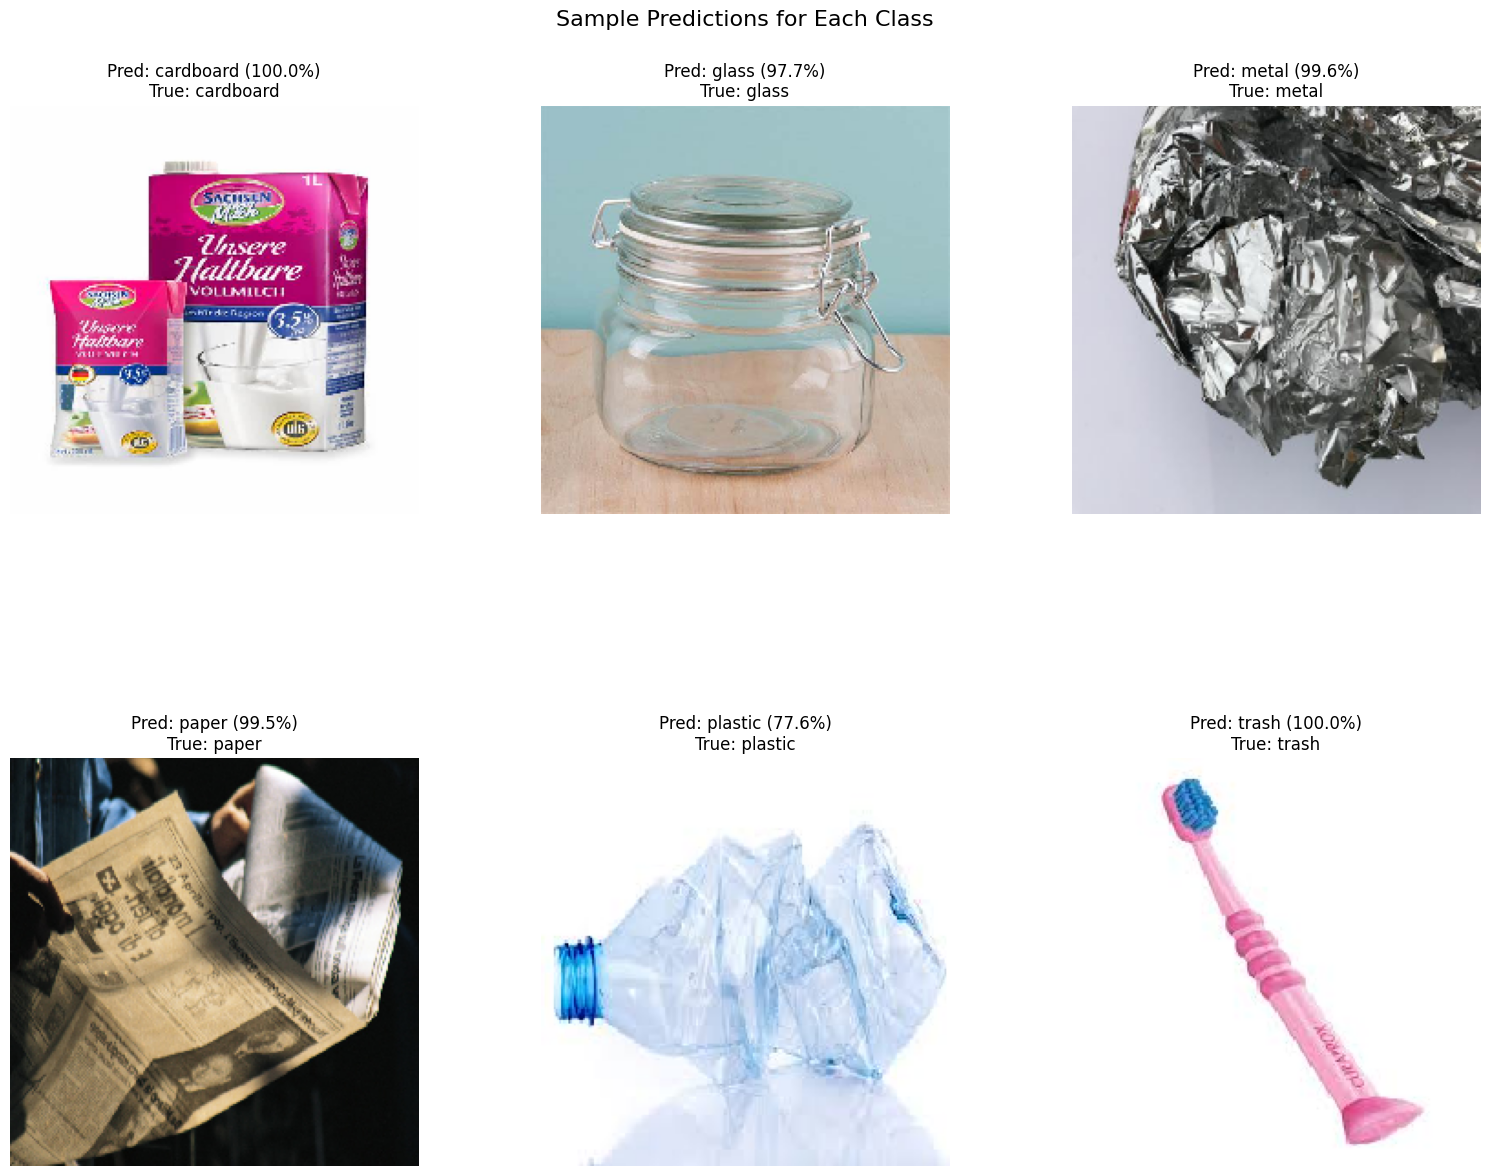

Predictions for one image from each class displayed.


In [42]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Get unique class labels from test_data
unique_classes_indices = np.unique(test_data.classes)

plt.figure(figsize=(15, 12)) # Adjusted figure size to accommodate more space

for i, class_idx in enumerate(unique_classes_indices):
    # Find the first image in the test_data that belongs to this class
    sample_idx = np.where(test_data.classes == class_idx)[0][0]

    sample_image_filepath = test_data.filepaths[sample_idx]
    sample_true_label = class_labels[class_idx]

    # Load the image and resize it to the target size
    img = image.load_img(sample_image_filepath, target_size=(image_height, image_width))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) # Add batch dimension
    img_array = img_array / 255.0  # Rescale to [0, 1] as done during preprocessing

    # Make prediction
    predictions = model.predict(img_array, verbose=0) # verbose=0 to suppress prediction output
    predicted_class_index = np.argmax(predictions[0])
    predicted_class_label = class_labels[predicted_class_index]
    confidence = np.max(predictions[0]) * 100

    # Display the image and prediction
    plt.subplot(2, 3, i + 1) # Arrange plots in a 2x3 grid (adjust if num_classes changes)
    plt.imshow(img)
    plt.title(f"Pred: {predicted_class_label} ({confidence:.1f}%)\nTrue: {sample_true_label}")
    plt.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust tight_layout to make space for suptitle
plt.subplots_adjust(wspace=0.3, hspace=0.4) # Add horizontal and vertical space
plt.suptitle('Sample Predictions for Each Class', y=1.00, fontsize=16) # Add a main title
plt.show()

print("Predictions for one image from each class displayed.")

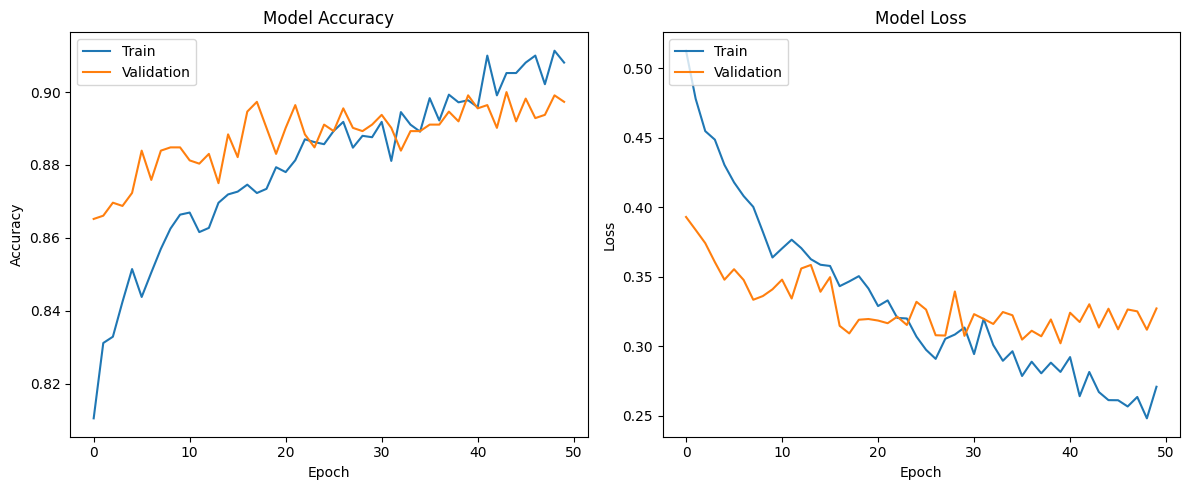

In [43]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.tight_layout()
plt.show()

FileUpload(value=(), accept='image/*', description='Upload')

Button(description='Predict', style=ButtonStyle())

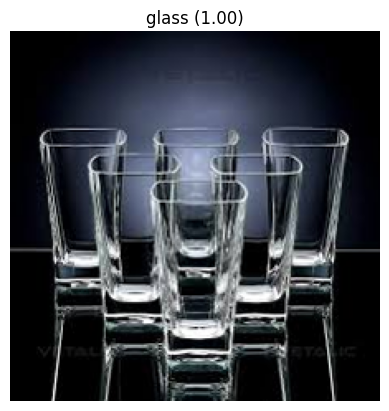

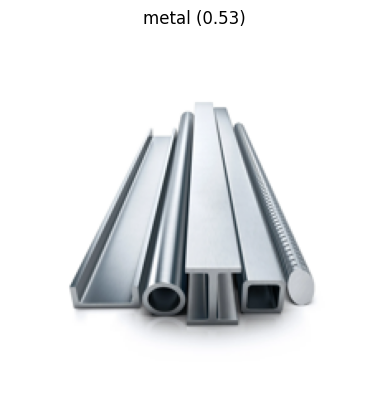

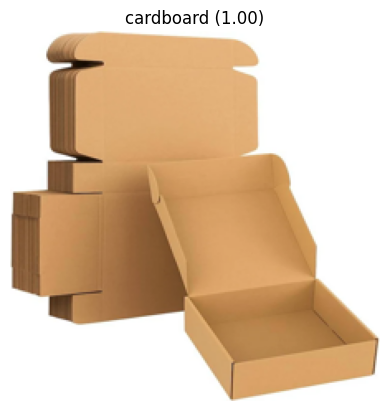

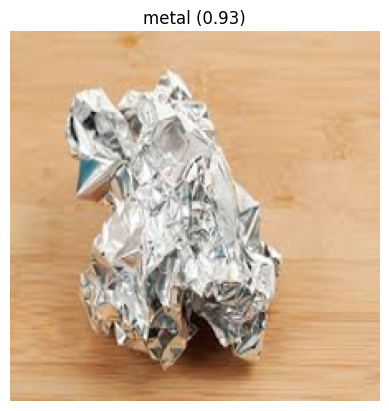

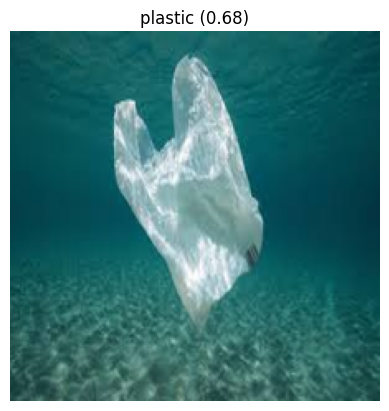

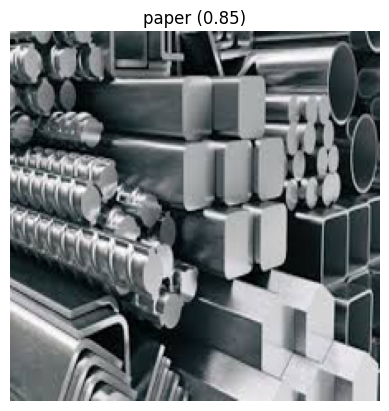

In [ ]:
import numpy as np
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from PIL import Image
import io

# Load model
model = load_model("best_model.keras")

# Class names
class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']

# Upload widget
upload = widgets.FileUpload(accept='image/*', multiple=False)
display(upload)

# Button
button = widgets.Button(description="Predict")
display(button)

def on_button_click(b):
    if len(upload.value) == 0:
        print("⚠️ Please upload an image first")
        return

    # ✅ FIXED HERE
    if isinstance(upload.value, dict):
        file_info = list(upload.value.values())[0]
        content = file_info['content']
    else:
        content = upload.value[0]['content']

    # Read image
    img = Image.open(io.BytesIO(content)).convert('RGB')
    img = img.resize((224, 224))

    # Preprocess
    img_array = np.array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    pred = model.predict(img_array)
    pred_class = np.argmax(pred)
    confidence = np.max(pred)

    # Show result
    plt.imshow(img)
    plt.title(f"{class_names[pred_class]} ({confidence:.2f})")
    plt.axis('off')
    plt.show()

button.on_click(on_button_click)

FileUpload(value=(), accept='image/*', description='Upload')

Button(description='Calculate IoU', style=ButtonStyle())

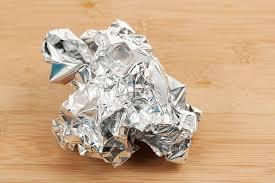

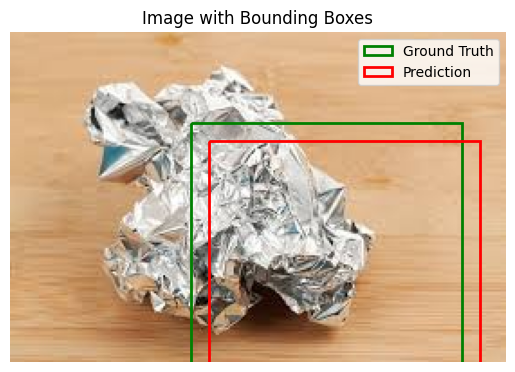

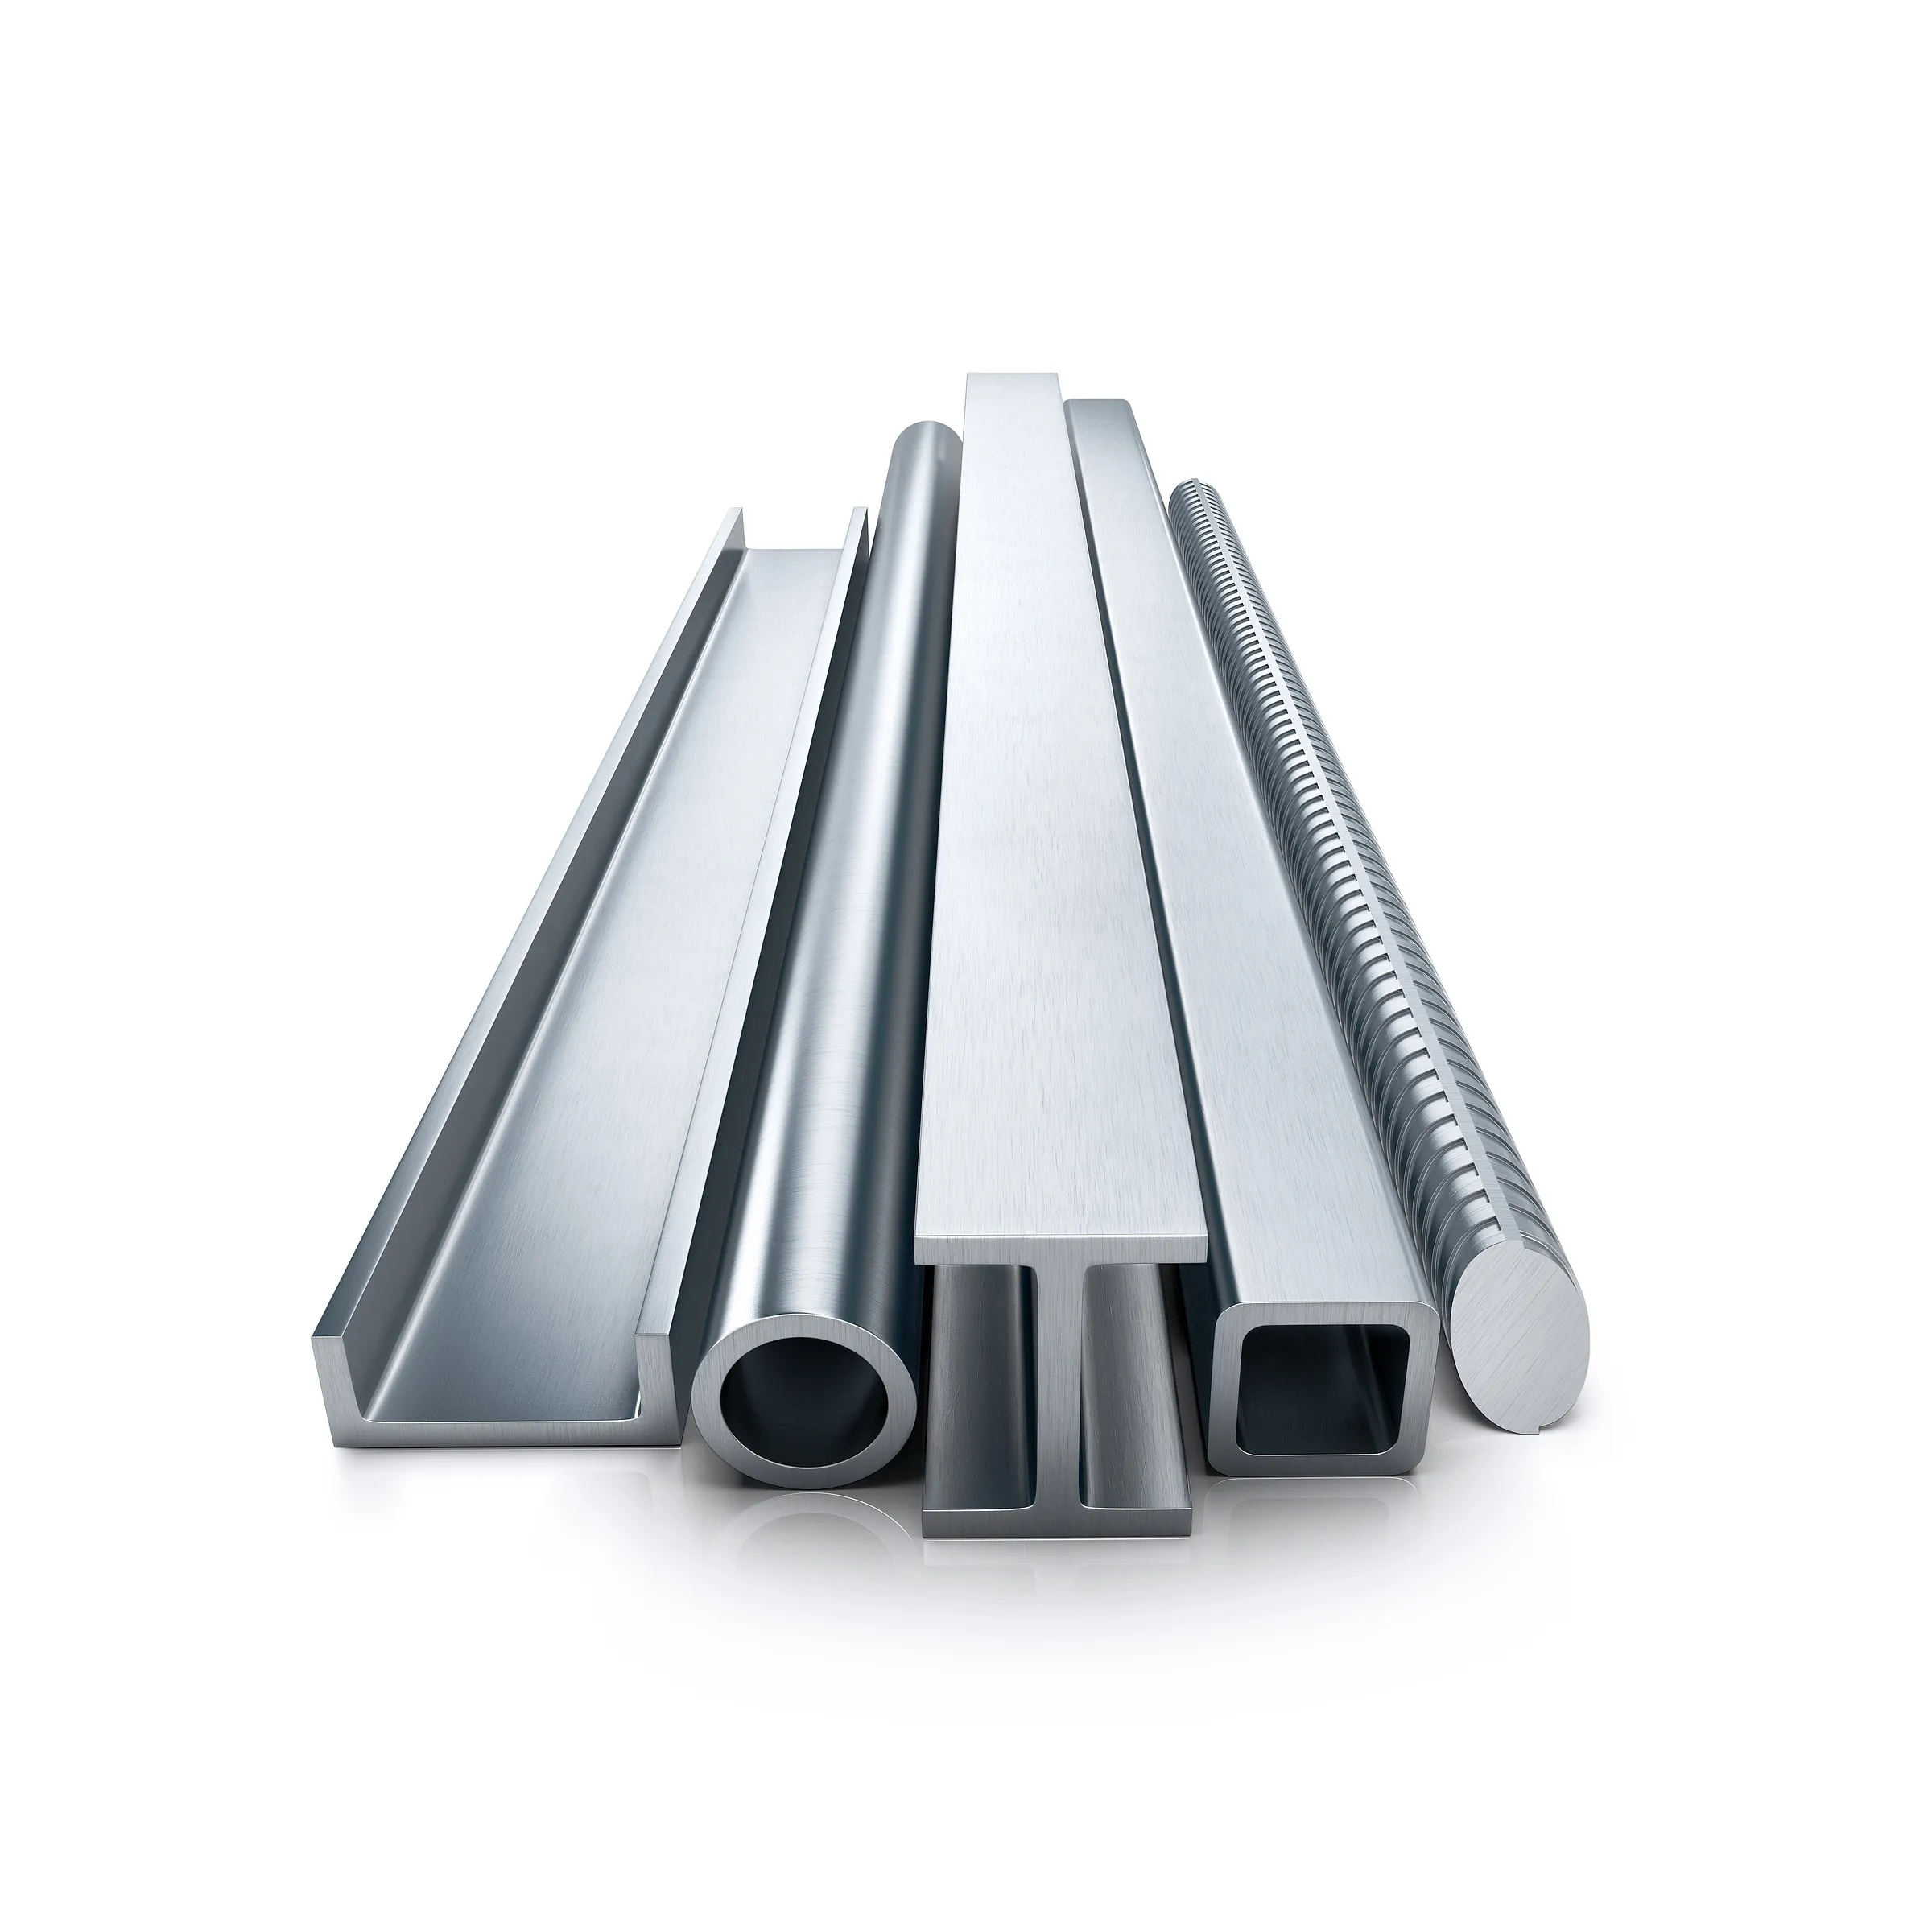

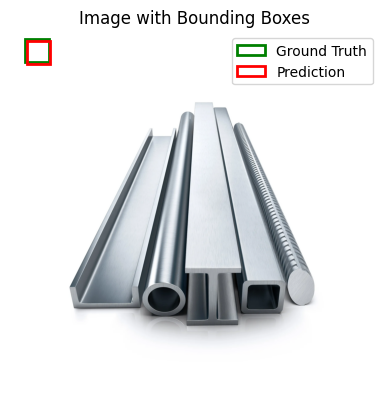

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display, Image
from PIL import Image as PILImage # Renamed to avoid conflict with IPython.display.Image
import io

def calculate_iou(boxA, boxB):
    """
    Calculates the Intersection over Union (IoU) of two bounding boxes.

    Args:
        boxA (list or np.array): Bounding box coordinates [x1, y1, x2, y2].
        boxB (list or np.array): Bounding box coordinates [x1, y1, x2, y2].

    Returns:
        float: The IoU value.
    """

    # Determine the coordinates of the intersection rectangle
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    # Compute the area of the intersection rectangle
    interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)

    # Compute the area of both the prediction and ground-truth rectangles
    boxAArea = (boxA[2] - boxA[0] + 1) * (boxA[3] - boxA[1] + 1)
    boxBArea = (boxB[2] - boxB[0] + 1) * (boxB[3] - boxB[1] + 1)

    # Compute the intersection over union by taking the intersection
    # area and dividing it by the sum of prediction + ground-truth
    # areas - the intersection area
    iou = interArea / float(boxAArea + boxBArea - interArea)

    # Return the intersection over union value
    return iou

# --- User Input Section ---
# 1. Upload your image file. A file chooser will appear.
upload = widgets.FileUpload(accept='image/*', multiple=False)
display(upload)

# 2. Define your ground truth and predicted bounding boxes here
# Format: [x1, y1, x2, y2]
# (x1, y1) = top-left corner, (x2, y2) = bottom-right corner

ground_truth_box = [100, 50, 250, 200]  # Example Ground Truth Box for an object (replace with yours!)
predicted_box = [110, 60, 260, 210]     # Example Predicted Box for the same object (replace with yours!)

# --- End User Input Section ---

button = widgets.Button(description="Calculate IoU")
display(button)

def on_button_click(b):
    if not upload.value:
        print("⚠️ Please upload an image first")
        return

    # Handle potential differences in upload.value format
    # ipywidgets.FileUpload.value can be a dict or a tuple of dicts
    file_data = None
    image_filename = 'uploaded_image'

    if isinstance(upload.value, dict):
        # Expected format: {'filename': {'content': b'...', 'metadata': {...}}}
        image_filename = next(iter(upload.value.keys())) # Get the first filename
        file_data = upload.value[image_filename]
    elif isinstance(upload.value, (list, tuple)):
        # This handles cases where upload.value is a tuple/list of dicts
        # e.g., ([{'content': b'...' , 'metadata': {...}}],)
        if upload.value:
            file_data = upload.value[0]
            image_filename = file_data.get('metadata', {}).get('name', 'uploaded_image')
    
    if not file_data:
        print("⚠️ Could not process uploaded file data.")
        return

    content = file_data['content']

    print(f"Displaying image: {image_filename}")
    display(Image(data=content, width=400))

    # Load image for plotting bounding boxes using PIL
    img_pil = PILImage.open(io.BytesIO(content))
    img = np.array(img_pil) # Convert PIL Image to NumPy array for matplotlib

    fig, ax = plt.subplots(1)
    ax.imshow(img)

    # Create a Rectangle patch for Ground Truth
    rect_gt = patches.Rectangle(
        (ground_truth_box[0], ground_truth_box[1]),
        ground_truth_box[2] - ground_truth_box[0],
        ground_truth_box[3] - ground_truth_box[1],
        linewidth=2, edgecolor='g', facecolor='none', label='Ground Truth'
    )
    ax.add_patch(rect_gt)

    # Create a Rectangle patch for Predicted Box
    rect_pred = patches.Rectangle(
        (predicted_box[0], predicted_box[1]),
        predicted_box[2] - predicted_box[0],
        predicted_box[3] - predicted_box[1],
        linewidth=2, edgecolor='r', facecolor='none', label='Prediction'
    )
    ax.add_patch(rect_pred)

    plt.title('Image with Bounding Boxes')
    plt.legend()
    plt.axis('off')
    plt.show()

    # Calculate IoU using the function defined previously
    iou_value = calculate_iou(ground_truth_box, predicted_box)

    print(f"\nCalculated IoU between Ground Truth {ground_truth_box} and Predicted {predicted_box}: {iou_value:.4f}")

button.on_click(on_button_click)